In [42]:
import os
os.environ['DRJIT_LIBLLVM_PATH'] = '/usr/lib/x86_64-linux-gnu/libLLVM-20.so'
import drjit as drjit

%env DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"

env: DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"


In [43]:
import numpy as np
import tensorflow as tf

import sionna
# Import or install Sionna
try:
    import sionna.rt
except ImportError as e:
    import os
    os.system("pip install sionna-rt")
    import sionna.rt

# Other imports
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from scipy import constants

no_preview = False # Toggle to False to use the preview widget
import mitsuba as mi
# mi.set_variant("cuda_rgb")
# Import relevant components from Sionna RT
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera,\
                      PathSolver, RadioMapSolver, subcarrier_frequencies

In [44]:
MIN_LAT = 51.502
MIN_LON = -0.027
MAX_LAT = 51.5075
MAX_LON = -0.0125

# Longitude [-0.027, -0.0125]
# Latitude [51.502, 51.5075]

def geographic_to_cartesian(lat, lon, alt=0):
    """Convert geographic coordinates to Cartesian coordinates. Needed to assure
    cross-compatibility with MATLAB and Sionna RT, which uses Cartesian coordinates."""

     # Midpoint origin (degrees)
    lat0 = 0.5 * (MIN_LAT + MAX_LAT)
    lon0 = 0.5 * (MIN_LON + MAX_LON)

    dlat = lat - lat0
    dlon = lon - lon0

    # Meters per degree (simple approximation)
    meters_per_deg_lat = 111_132.0
    meters_per_deg_lon = 111_320.0 * np.cos(np.radians(lat0))

    east  = dlon * meters_per_deg_lon
    north = dlat * meters_per_deg_lat
    up    = alt
    return np.array([east, north, up])

In [45]:
# Change colors for visualization
sionna.rt.radio_materials.itu_material.ITURadioMaterial.ITU_MATERIAL_COLORS["metal"] = (
    0.1, 0.1, 0.1,  # Dark Gray color
)

sionna.rt.radio_materials.itu_material.ITURadioMaterial.ITU_MATERIAL_COLORS["concrete"] = (
    0.6, 0.6, 0.6,  # gray color
)

# Path Visualization

In [23]:
scene = load_scene("./wharf_scene_v3/canarywharf3.xml", merge_shapes=False)
# scene.preview()

scene.frequency = 28e9  # 11 GHz (Ku-band downlink)

# Configure antenna array for all transmitters
scene.tx_array = PlanarArray(num_rows=2,
                             num_cols=2,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="tr38901",
                             polarization="V")

# Configure antenna array for all receivers
scene.rx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso",
                             polarization="cross")

# Create transmitter

tx_position = geographic_to_cartesian(51.50375, -0.01843, alt=10)

print(tx_position)

tx = Transmitter(name="tx",
                 position=tx_position,
                 display_radius=10)

# Add transmitter instance to scene
scene.add(tx)
tx.power_dbm = 37 # Transmit power in dBm


rx_position = geographic_to_cartesian(51.50216, -0.01769, alt=5)
# print("Receiver position (x,y,z) in meters:", rx_position)
# Create a receiver
rx = Receiver(name="rx",
              position=rx_position,
              display_radius=10)

print(rx_position)

# Add receiver instance to scene
scene.add(rx)

tx.look_at(rx) # Transmitter points towards receiver

[  91.46426071 -111.132        10.        ]
[ 142.73967959 -287.83188       5.        ]


In [20]:
# The same path solver can be used with multiple scenes
p_solver  = PathSolver()
num_samples = (2**32 - 1) // 4
# Compute propagation paths
paths = p_solver(scene=scene,
                 max_depth=5,
                 los=True,
                 specular_reflection=True,
                 diffuse_reflection=False,
                 refraction=True,
                 diffraction=False,
                 synthetic_array=False,
                 max_num_paths_per_src=200_000,
                 samples_per_src=num_samples,
                 seed=22,
                 beamforming=True,
                 beam_angle=3*np.pi/4)

In [8]:
scene.preview(paths=paths)  # Visualize the scene

In [21]:
num_paths = paths.a[0][0,0,0,0,:].shape[0]
print(f"Number of paths between tx and rx: {num_paths}")
coefficients = paths.a[0][0,0,0,0,0:num_paths]
# print("Path details:")
path_loss_dB = -20 * np.log10(np.abs(coefficients))
print(f"Path loss (dB): {path_loss_dB} dB")

Number of paths between tx and rx: 15
Path loss (dB): [163.48047  209.42743  110.29503  107.30823  112.724335 116.57792
 151.87056  157.04492  146.90398  144.12308  158.47108  155.97772
 152.87141  149.15955         inf] dB


/tmp/ipykernel_2674541/1361007593.py:5: RuntimeWarning: divide by zero encountered in log10
  path_loss_dB = -20 * np.log10(np.abs(coefficients))


Channel Gain: 3.5508374e-11
Channel Gain (dB): -104.49668884277344


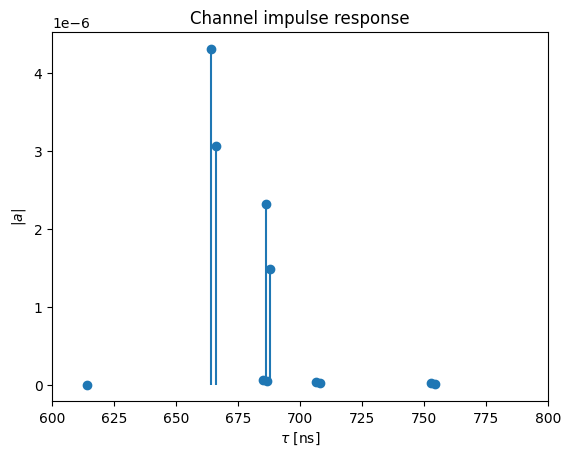

In [22]:
a, tau = paths.cir(normalize_delays=False, out_type="numpy")

t = tau[0,0,0,0,:]/1e-9 # Scale to ns
a_abs = np.abs(a)[0,0,0,0,:,0]

print("Channel Gain:", np.sum(a_abs**2) )
print("Channel Gain (dB):", 10*np.log10( np.sum(a_abs**2) ) )

# And plot the CIR
plt.figure()
plt.title("Channel impulse response")
plt.stem(t, a_abs,basefmt=" ")
plt.xlabel(r"$\tau$ [ns]")
plt.xlim(600, 800)
plt.ylabel(r"$|a|$");

In [61]:
print(a.shape)
print(tau.shape)

(1, 2, 1, 4, 13, 1)
(1, 2, 1, 4, 13)


# Time-Delay(Tau) Verification
Verified for Directional Transmitter, with 1e7 rays generated

In [46]:
# Code borrowed from test_scene_red_square.ipynb in Sionna RT Report

def get_path_vertices(paths, rx_idx=0, rx_ant_idx=0, tx_idx=0, tx_ant_idx=0, path_idx=0):
    """
    Calculate total distance for a specific path from vertices.
    
    Parameters:
    -----------
    paths : sionna.rt.Paths
        Paths object from PathSolver
    rx_idx : int
        Receiver index
    rx_ant_idx : int
        Receiver antenna index
    tx_idx : int
        Transmitter index
    tx_ant_idx : int
        Transmitter antenna index
    path_idx : int
        Path index
    
    Returns:
    --------
    total_distance : float
        Total path length in meters
    segment_distances : list
        Distance of each segment
    valid_vertices : numpy.ndarray
        Array of valid vertex positions
    """
    # Get vertices for this path
    # Shape: [max_depth, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, 3]
    vertices = paths.vertices.numpy()
    
    # Extract vertices for specific path
    path_vertices = vertices[:, rx_idx, rx_ant_idx, tx_idx, tx_ant_idx, path_idx, :]
    
    # Get objects to identify valid vertices
    objects = paths.objects.numpy()
    path_objects = objects[:, rx_idx, rx_ant_idx, tx_idx, tx_ant_idx, path_idx]
    
    # Filter valid vertices (non-zero and valid object IDs)
    valid_vertices = []
    for depth_idx in range(path_vertices.shape[0]):
        vertex = path_vertices[depth_idx]

        obj_id = path_objects[depth_idx]

        if obj_id != 4294967295:  # INVALID_SHAPE constant

            valid_vertices.append(vertex)
            
    
    valid_vertices = np.array(valid_vertices)

    path_depth = valid_vertices.shape[0]


    return valid_vertices, path_depth
    
def calculate_path_distance(tx_pos, rx_pos, valid_vertices):


    # Calculate distances between consecutive vertices
    segment_distances = []
    total_distance = 0.0
    if valid_vertices.size == 0:
        valid_vertices_all = np.vstack([tx_pos, rx_pos])
    else:    
        valid_vertices_all = np.vstack([tx_pos, valid_vertices, rx_pos])

    
    for i in range(len(valid_vertices_all) - 1):
        segment_dist = np.linalg.norm(valid_vertices_all[i+1] - valid_vertices_all[i])
        segment_distances.append(segment_dist)
        total_distance += segment_dist

    print("Total path distance:", total_distance)    
    
    return total_distance, valid_vertices_all



In [62]:

# ============================================
# CALCULATE DISTANCES FOR ALL PATHS
# ============================================

num_paths = paths.a[0][0,0,0,0,:].shape[0]

print("=" * 70)
print("PATH DISTANCES ANALYSIS")
print("=" * 70)
print(f"\nTotal paths found: {num_paths}")
print(f"TX position: {tx.position.numpy()}")
print(f"RX position: {rx.position.numpy()}")

c = 3e8  # Speed of light [m/s]

# Store results for plotting
path_distances = []
path_delays = []
path_coefficients = []
path_depths = []

# print(tau)
vert_path = {}

for path_idx in range(num_paths):
    # Calculate distance from vertices
    # distance, segments, vertices = calculate_path_distance(paths, path_idx=path_idx)
    path_vertices, path_depth = get_path_vertices(paths, path_idx=path_idx)
    path_depths.append(path_depth)
    print('Path vertices shape:',path_vertices.shape)
    distance, vertic_o_p = calculate_path_distance(tx.position.numpy().T, rx.position.numpy().T, path_vertices)

    vert_path[path_idx] = vertic_o_p

    
    # Get delay from CIR
    delay = tau[0,0,0,0,path_idx]
    
    # Get path coefficient
    a_path = paths.a[0][0,0,0,0,path_idx]
    
    sort_idx = np.argsort(path_depths)
    

    # Store for analysis
    path_distances.append(distance)
    path_delays.append(delay)
    path_coefficients.append(np.abs(a_path))
    
    print(f"\n{'='*70}")
    print(f"PATH {path_idx}")
    print(f"{'='*70}")
    

    
    # Delay information
    print(f"\n2. DELAY VERIFICATION:")
    print(f"   Delay from CIR (τ): {delay*1e9:.4f} ns")
    expected_delay = distance / c
    print(f"   Expected delay (d/c): {expected_delay*1e9:.4f} ns")
    print(f"   Match: {np.isclose(delay, expected_delay, rtol=1e-3)}")
    
    # Path coefficient
    print(f"\n3. PATH STRENGTH:")
    print(f"   |a| = {np.abs(a_path):.6e}")
    print(f"   |a| (dB) = {20*np.log10(np.abs(a_path)):.2f} dB")
    

# ============================================
# SUMMARY STATISTICS
# ============================================

print(f"\n{'='*70}")
print("SUMMARY STATISTICS")
print(f"{'='*70}")

sort_idx = np.argsort(path_distances)


path_distances = np.array(path_distances)
path_delays = np.array(path_delays)
path_coefficients = np.array(path_coefficients)
path_depths = np.array(path_depths)


# ============================================
# VISUALIZATION
# ============================================

# import matplotlib.pyplot as plt
# import numpy as np
# from matplotlib.cm import ScalarMappable
# from matplotlib.colors import Normalize

# fig, ax = plt.subplots(1, 1, figsize=(14, 10))

# # Calculate path loss
# path_loss_dB = -20 * np.log10(path_coefficients)

# # Normalize colors based on path loss
# norm = Normalize(vmin=path_loss_dB.min(), vmax=path_loss_dB.max())
# cmap =  plt.cm.viridis   # Red (high loss) to Green (low loss)

# # Plot stems with color coding
# for i, (delay, coeff, loss, distance) in enumerate(zip(path_delays*1e9, 
#                                                         path_coefficients, 
#                                                         path_loss_dB,
#                                                         path_distances)):
#     color = cmap(norm(loss))
    
#     # Plot stem
#     ax.plot([delay, delay], [0, coeff], color=color, linewidth=2.5, alpha=0.7)
#     ax.plot(delay, coeff, 'o', color=color, markersize=10, 
#            markeredgecolor='black', markeredgewidth=1)
    
#     # Add annotation
#     annotation_text = (f'P{i}\n'
#                       f'{loss:.1f}dB\n'
#                       f'{distance:.1f}m')
    
#     ax.annotate(annotation_text,
#                 xy=(delay, coeff),
#                 xytext=(0, 15),
#                 textcoords='offset points',
#                 ha='center',
#                 fontsize=12,
#                 bbox=dict(boxstyle='round,pad=0.3', 
#                          facecolor='white', 
#                          edgecolor=color,
#                          linewidth=2,
#                          alpha=0.9))

# # Add colorbar
# sm = ScalarMappable(cmap=cmap, norm=norm)
# sm.set_array([])
# cbar = plt.colorbar(sm, ax=ax, label='Path Loss [dB]')
# cbar.ax.tick_params(labelsize=10)

# ax.set_xlabel('Delay [ns]', fontsize=12, fontweight='bold')
# ax.set_ylabel('|a|', fontsize=12, fontweight='bold')
# ax.set_title('Channel Impulse Response (Color-coded by Path Loss)', 
#             fontsize=14, fontweight='bold')
# ax.grid(True, alpha=0.3)
# ax.set_ylim(bottom=0)

# plt.tight_layout()
# plt.show()

PATH DISTANCES ANALYSIS

Total paths found: 13
TX position: [[  91.464264]
 [-111.132   ]
 [  10.      ]]
RX position: [[ 142.73969]
 [-287.83188]
 [   5.     ]]
Path vertices shape: (1, 3)
Total path distance: 199.12255477905273

PATH 0

2. DELAY VERIFICATION:
   Delay from CIR (τ): 664.2026 ns
   Expected delay (d/c): 663.7418 ns
   Match: True

3. PATH STRENGTH:
   |a| = 4.311108e-06
   |a| (dB) = -107.31 dB
Path vertices shape: (2, 3)
Total path distance: 205.36148738861084

PATH 1

2. DELAY VERIFICATION:
   Delay from CIR (τ): 685.0202 ns
   Expected delay (d/c): 684.5383 ns
   Match: True

3. PATH STRENGTH:
   |a| = 6.220807e-08
   |a| (dB) = -144.12 dB
Path vertices shape: (2, 3)
Total path distance: 205.74668407440186

PATH 2

2. DELAY VERIFICATION:
   Delay from CIR (τ): 686.2987 ns
   Expected delay (d/c): 685.8223 ns
   Match: True

3. PATH STRENGTH:
   |a| = 2.310911e-06
   |a| (dB) = -112.72 dB
Path vertices shape: (3, 3)
Total path distance: 211.79197216033936

PATH 3

2.

# SBR Sanity Check: CIR vs. Number of Sample Rays

# Isotropic Antenna

In [47]:
scene = load_scene("./wharf_scene_v3/canarywharf3.xml", merge_shapes=False)
# scene.preview()
scene.frequency = 11.7e9  


scene.tx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso",
                             polarization="V")

# Configure antenna array for all receivers
scene.rx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso",
                             polarization="cross")

# Create transmitter

tx_position = geographic_to_cartesian(51.50375, -0.01843, alt=10)
# Create a transmitter

tx = Transmitter(name="tx",
                 position=tx_position,
                 display_radius=10)

# Add transmitter instance to scene
scene.add(tx)
tx.power_dbm = 43 # Transmit power in dBm


rx_position = geographic_to_cartesian(51.50216, -0.01769, alt=5)
# print("Receiver position (x,y,z) in meters:", rx_position)
# Create a receiver
rx = Receiver(name="rx",
              position=rx_position,
              display_radius=10)

# Add receiver instance to scene
scene.add(rx)

tx.look_at(rx) # Transmitter points towards receiver
p_solver  = PathSolver()
    # Compute propagation paths
paths = p_solver(scene=scene,
                     max_depth=5,
                     los=True,
                     specular_reflection=True,
                     diffuse_reflection=True,
                     refraction=False,
                     diffraction=False,
                     synthetic_array=False,
                     max_num_paths_per_src=(2**24 - 1),
                     samples_per_src=n,)
num_paths = paths.a[0][0,0,0,0,:].shape[0]
# print(f"Number of paths between tx and rx: {num_paths}")

a, tau = paths.cir(normalize_delays=False, out_type="numpy")

t = tau[0,0,0,0,:]/1e-9 # Scale to ns
a_abs = np.abs(a)[0,0,0,0,:,0]

interactions = paths.interactions.numpy()
    
interactions = interactions[:,0,0,:]

RuntimeError: [parser.cpp:1708] At string (line 5, col 6): failed to instantiate bsdf plugin of type "itu-radio-material": [PluginManager] Plugin "itu-radio-material" not found!

In [66]:
# loop through different number of samples
num_samples = np.array([1e4, 1e5, 1e6, 1e7], dtype=np.int32)
CIR_iso = []

for n in num_samples:
    print(f"Computing paths with {n} samples...")
    p_solver  = PathSolver()
    # Compute propagation paths
    paths = p_solver(scene=scene,
                     max_depth=5,
                     los=True,
                     specular_reflection=True,
                     diffuse_reflection=False,
                     refraction=True,
                     diffraction=False,
                     synthetic_array=False,
                     max_num_paths_per_src=n,
                     samples_per_src=n,
                     seed=21)
    num_paths = paths.a[0][0,0,0,0,:].shape[0]
    print(f"Number of paths between tx and rx: {num_paths}")
    
    a, tau = paths.cir(normalize_delays=False, out_type="numpy")

    t = tau[0,0,0,0,:]/1e-9 # Scale to ns
    a_abs = np.abs(a)[0,0,0,0,:,0]
    
    print("Channel Gain:", np.sum(a_abs**2) )
    print("Channel Gain (dB):", 10*np.log10( np.sum(a_abs**2) ) )
    CIR_iso.append((t, a_abs))


Computing paths with 10000 samples...
Number of paths between tx and rx: 9
Channel Gain: 7.127177e-12
Channel Gain (dB): -111.47082328796387
Computing paths with 100000 samples...
Number of paths between tx and rx: 10
Channel Gain: 7.1833702e-12
Channel Gain (dB): -111.43671989440918
Computing paths with 1000000 samples...
Number of paths between tx and rx: 12
Channel Gain: 7.1917086e-12
Channel Gain (dB): -111.43167495727539
Computing paths with 10000000 samples...
Number of paths between tx and rx: 13
Channel Gain: 7.192329e-12
Channel Gain (dB): -111.43130302429199


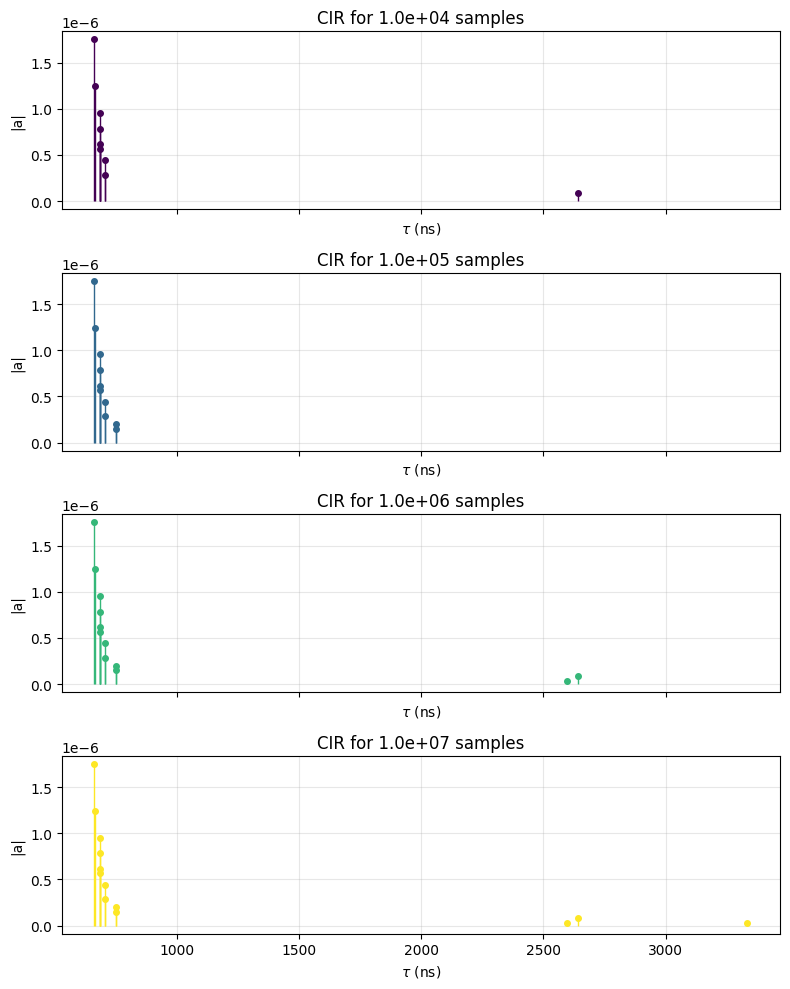

In [77]:
cmap = mpl.colormaps['viridis']
C = cmap(np.linspace(0, 1, len(CIR_iso)))

fig, axes = plt.subplots(
    nrows=len(CIR_iso),
    ncols=1,
    figsize=(8, 10),
    sharex=True
)

for i, (ax, n) in enumerate(zip(axes, num_samples)):
    t, a_abs = CIR_iso[i]
    markerline, stemlines, baseline = ax.stem(t, a_abs,basefmt=" ")

    # Color configuration
    ax.set_title(f"CIR for {n:.1e} samples")
    plt.setp(markerline, color=C[i], markersize=4)
    plt.setp(stemlines, color=C[i], linewidth=1.0)

    ax.grid(True, alpha=0.3)
    ax.set_ylabel(r"|a|")
    ax.set_xlabel(r"$\tau$ (ns)")

# plt.xlim(600, 800)
plt.tight_layout()
plt.show()


# Directional Antenna

In [ ]:
scene = load_scene("./wharf_scene_v3/canarywharf3.xml", merge_shapes=False)
# scene.preview()
scene.frequency = 28e9  


scene.tx_array = PlanarArray(num_rows=2,
                             num_cols=2,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="tr38901",
                             polarization="V")

# Configure antenna array for all receivers
scene.rx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso",
                             polarization="cross")

# Create transmitter

tx_position = geographic_to_cartesian(51.50375, -0.01843, alt=10)
# Create a transmitter

tx = Transmitter(name="tx",
                 position=tx_position,
                 display_radius=10)

# Add transmitter instance to scene
scene.add(tx)
tx.power_dbm = 37 # Transmit power in dBm


rx_position = geographic_to_cartesian(51.50216, -0.01769, alt=5)
# print("Receiver position (x,y,z) in meters:", rx_position)
# Create a receiver
rx = Receiver(name="rx",
              position=rx_position,
              display_radius=10)

# Add receiver instance to scene
scene.add(rx)

tx.look_at(rx) # Transmitter points towards receiver

In [102]:
# loop through different number of samples
num_samples = np.array([1e4, 1e5, 1e6, 1e7], dtype=np.int32)
CIR_dir = []

for n in num_samples:
    print(f"Computing paths with {n} samples...")
    p_solver  = PathSolver()
    # Compute propagation paths
    paths = p_solver(scene=scene,
                     max_depth=5,
                     los=True,
                     specular_reflection=True,
                     diffuse_reflection=False,
                     refraction=True,
                     diffraction=False,
                     synthetic_array=False,
                     max_num_paths_per_src=n,
                     samples_per_src=n,
                     seed=35)
    num_paths = paths.a[0][0,0,0,0,:].shape[0]
    print(f"Number of paths between tx and rx: {num_paths}")
    
    a, tau = paths.cir(normalize_delays=False, out_type="numpy")

    t = tau[0,0,0,0,:]/1e-9 # Scale to ns
    a_abs = np.abs(a)[0,0,0,0,:,0]
    
    print("Channel Gain:", np.sum(a_abs**2) )
    print("Channel Gain (dB):", 10*np.log10( np.sum(a_abs**2) ) )
    CIR_dir.append((t, a_abs))
    

Computing paths with 10000 samples...
Number of paths between tx and rx: 9
Channel Gain: 7.0862476e-11
Channel Gain (dB): -101.4958381652832
Computing paths with 100000 samples...
Number of paths between tx and rx: 10
Channel Gain: 7.0863176e-11
Channel Gain (dB): -101.49579048156738
Computing paths with 1000000 samples...
Number of paths between tx and rx: 12
Channel Gain: 7.08646e-11
Channel Gain (dB): -101.4957046508789
Computing paths with 10000000 samples...
Number of paths between tx and rx: 13
Channel Gain: 7.086499e-11
Channel Gain (dB): -101.49568557739258


(<Figure size 640x480 with 1 Axes>,
 <Figure size 640x480 with 1 Axes>,
 <Figure size 640x480 with 2 Axes>)

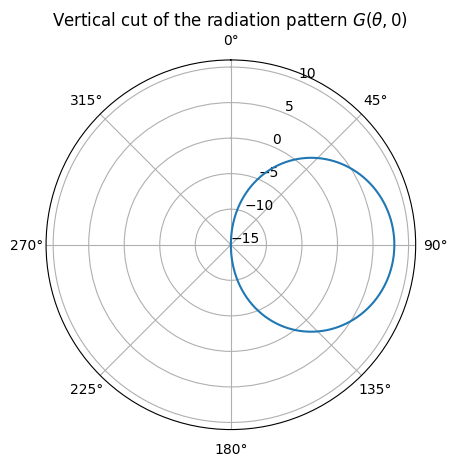

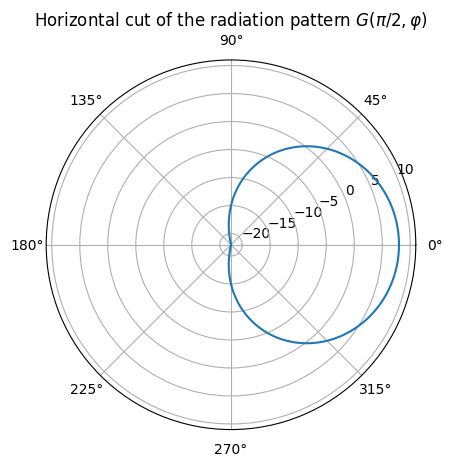

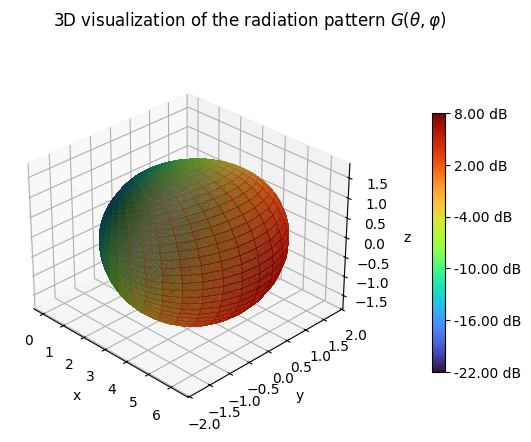

In [81]:
scene.tx_array.antenna_pattern.show()

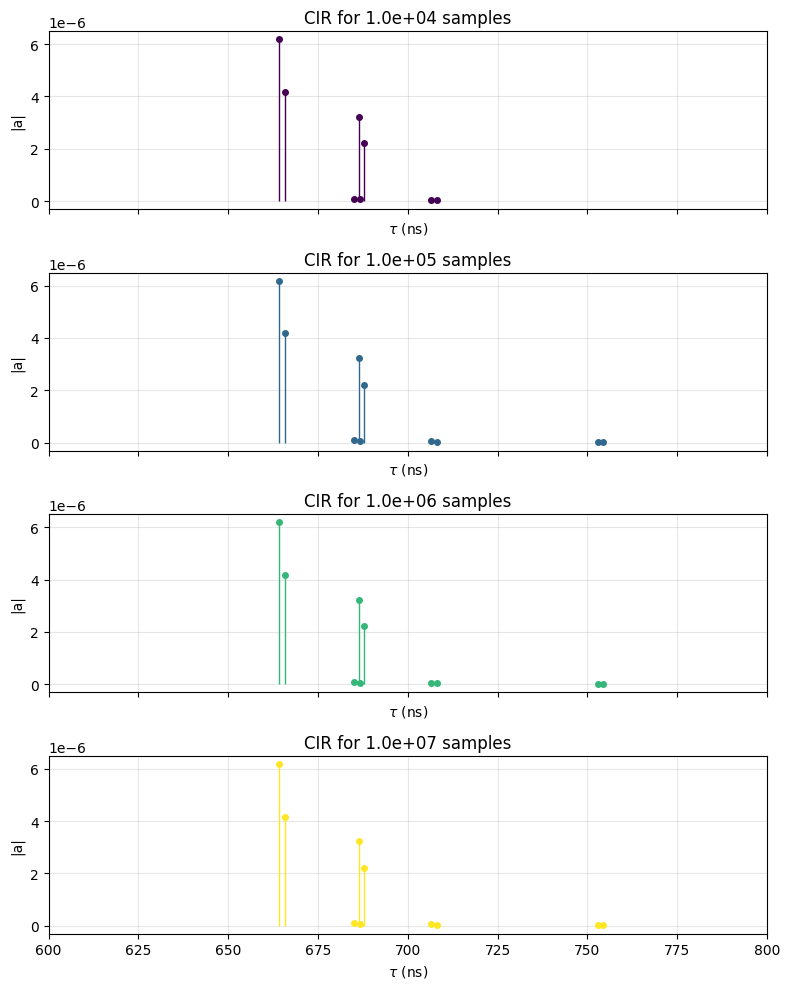

In [103]:
cmap = mpl.colormaps['viridis']
C = cmap(np.linspace(0, 1, len(CIR_dir)))

fig, axes = plt.subplots(
    nrows=len(CIR_dir),
    ncols=1,
    figsize=(8, 10),
    sharex=True
)

for i, (ax, n) in enumerate(zip(axes, num_samples)):
    t, a_abs = CIR_dir[i]
    markerline, stemlines, baseline = ax.stem(t, a_abs,basefmt=" ")

    # Color configuration
    ax.set_title(f"CIR for {n:.1e} samples")
    plt.setp(markerline, color=C[i], markersize=4)
    plt.setp(stemlines, color=C[i], linewidth=1.0)

    ax.grid(True, alpha=0.3)
    ax.set_ylabel(r"|a|")
    ax.set_xlabel(r"$\tau$ (ns)")

plt.xlim(600, 800)
plt.tight_layout()
plt.show()

# Overlay MATLAB/Sionna CIR

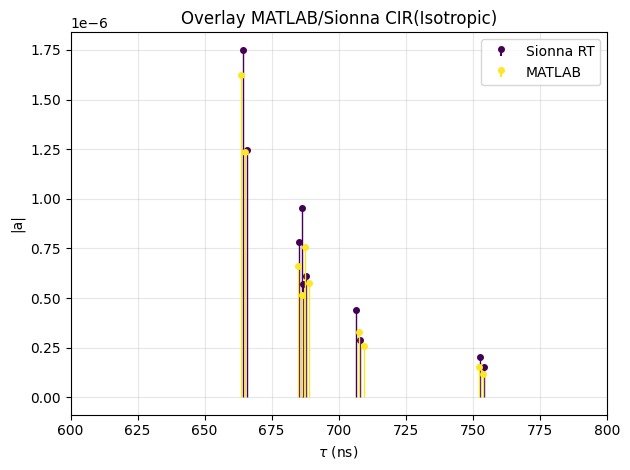

In [ ]:
import scipy.io as sio

data = sio.loadmat("cir_iso.mat")

mat_A = data["a_abs"]
mat_tau = data["tau"].squeeze()

cmap = mpl.colormaps['viridis']
C = cmap(np.linspace(0, 1, 2))

t, a_abs = CIR_iso[3]
markerline, stemlines, baseline = plt.stem(t, a_abs,basefmt=" ")

# Color configuration
plt.title(f"Overlay MATLAB/Sionna CIR(Isotropic)")
plt.setp(markerline, color=C[0], markersize=4)
plt.setp(stemlines, color=C[0], linewidth=1.0)

markerline, stemlines, baseline = plt.stem(mat_tau*1e9, mat_A,basefmt=" ")


plt.setp(markerline, color=C[1], markersize=4)
plt.setp(stemlines, color=C[1], linewidth=1.0)

plt.grid(True, alpha=0.3)
plt.ylabel(r"|a|")
plt.xlabel(r"$\tau$ (ns)")

plt.xlim(600, 800)

plt.legend(['Sionna RT', 'MATLAB'])
plt.tight_layout()
plt.show()

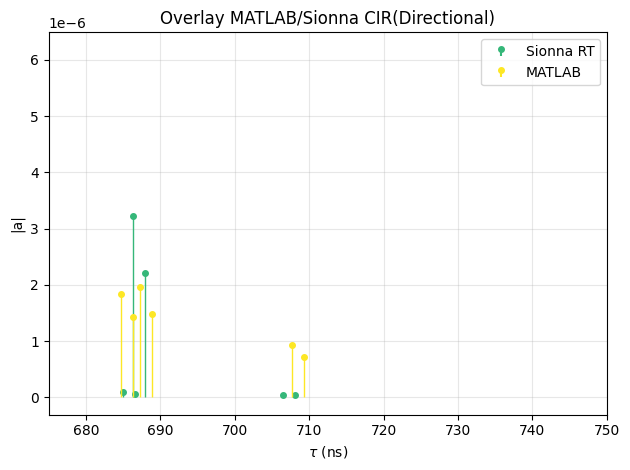

In [104]:
import scipy.io as sio

data = sio.loadmat("cir_dir.mat")

mat_A = data["a_abs"]
mat_tau = data["tau"].squeeze()

cmap = mpl.colormaps['viridis']
C = cmap(np.linspace(0, 1, 4))



t, a_abs = CIR_dir[3]
markerline, stemlines, baseline = plt.stem(t, a_abs,basefmt=" ")

# Color configuration
plt.title(f"Overlay MATLAB/Sionna CIR(Directional)")
plt.setp(markerline, color=C[2], markersize=4)
plt.setp(stemlines, color=C[2], linewidth=1.0)

markerline, stemlines, baseline = plt.stem(mat_tau*1e9, mat_A,basefmt=" ")


plt.setp(markerline, color=C[3], markersize=4)
plt.setp(stemlines, color=C[3], linewidth=1.0)

plt.grid(True, alpha=0.3)
plt.ylabel(r"|a|")
plt.xlabel(r"$\tau$ (ns)")

plt.xlim(675, 750)
plt.legend(['Sionna RT', 'MATLAB'])
plt.tight_layout()
plt.show()

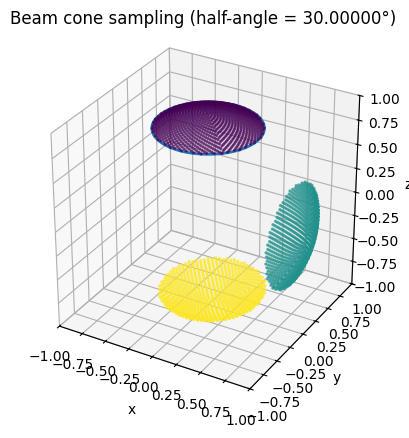

In [41]:
import numpy as np
import matplotlib.pyplot as plt

import drjit as dr
import mitsuba as mi

# Pick the variant you use in Sionna RT (most common)
# If you're using CUDA-AD in Sionna RT, this is usually right:
mi.set_variant("cuda_ad_rgb")  # or "llvm_ad_rgb" if CPU

def lattice(samples_per_src: int) -> mi.Point2f:
    r"""
    Generates a Fibonacci lattice of size ``num_points`` on the unit square
    :math:`[0, 1] \times [0, 1]`

    :param num_points: Size of the lattice
    """

    golden_ratio = (1.+dr.sqrt(mi.Float64(5.)))/2.
    ns = dr.arange(mi.Float64, 0, samples_per_src)

    x = ns/golden_ratio
    x = x - dr.floor(x)
    y = ns/(samples_per_src-1)
    
    #  # apply one random global shift
    # jitter = mi.Point2f(
    #     dr.rand(mi.Float64, 1),
    #     dr.rand(mi.Float64, 1)
    # )

    # return dr.fmod(mi.Point2f(x, y) + jitter, 1.0)

    return mi.Point2f(x, y)

def visualize_cone_mapping(
    num_sources=3,
    samples_per_src=2048,
    beam_angle_rad=0.01 * dr.pi / 180,   # default from your code
    src_orientations=None                # mi.Vector3f of length num_sources, in radians
):
    # --- Make example orientations if not provided (yaw, pitch, roll in radians) ---
    if src_orientations is None:
        # Example: a few different yaw/pitch/rolls (radians)
        yaw   = mi.Float([-90.0, 0, 90.0]) * dr.pi/180
        pitch = mi.Float([0.0, 0, 85]) * dr.pi/180
        roll  = mi.Float([0.0, 90.0,  0]) * dr.pi/180
        src_orientations = mi.Vector3f(yaw, pitch, roll)

    # --- 1) per-source lattice on unit square ---
    samples_on_square = lattice(samples_per_src)

    # --- 2) build per-sample yaw/pitch/roll in degrees (exactly like your code) ---
    yaw_deg   = dr.repeat(src_orientations.x, samples_per_src) * 180 / dr.pi
    pitch_deg = dr.repeat(src_orientations.y, samples_per_src) * 180 / dr.pi
    roll_deg  = dr.repeat(src_orientations.z, samples_per_src) * 180 / dr.pi

    # Compose rotation: R = Rz(yaw) * Ry(pitch) * Rx(roll)
    rotation = (
        mi.Transform4f.rotate(mi.Vector3f(0, 0, 1), yaw_deg) @
        mi.Transform4f.rotate(mi.Vector3f(0, 1, 0), pitch_deg) @
        mi.Transform4f.rotate(mi.Vector3f(1, 0, 0), roll_deg)
    )

    # --- 3) sample cone in local frame (+z boresight), then rotate to +x boresight ---
    cos_cutoff = mi.Float(dr.cos(beam_angle_rad))
    k_loc = mi.warp.square_to_uniform_cone(samples_on_square, cos_cutoff)

    R_local = mi.Transform4f.rotate(mi.Vector3f(0, 1, 0), 90.0)  # +z -> +x
    k_loc = R_local @ k_loc

    # --- 4) tile local samples across sources (same lattice per source) ---
    k_world = dr.tile(k_loc, num_sources)

    # --- 5) apply per-sample rotation (already repeated) ---
    k_world = rotation @ k_world

    # ----------------
    # Plot with matplotlib
    # ----------------
    # Bring back to host for plotting
    x = np.array(dr.detach(k_world.x))
    y = np.array(dr.detach(k_world.y))
    z = np.array(dr.detach(k_world.z))

    # Color by source index (simple segmentation because of samples-first ordering)
    src_idx = np.repeat(np.arange(num_sources), samples_per_src)

    fig = plt.figure()
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(x, y, z, s=2, alpha=0.6, c=src_idx)

    # Optional: draw the cone boundary ring for SOURCE 0 (in its final orientation)
    # Build ring in local +z cone, rotate to +x, then apply source-0 rotation.
    theta_max = float(beam_angle_rad)
    phi = np.linspace(0, 2*np.pi, 500)
    ring_local = np.stack([
        np.cos(theta_max) * np.ones_like(phi),   # NOTE: because boresight is +x after R_local
        np.sin(theta_max) * np.sin(phi),
        np.sin(theta_max) * np.cos(phi),
    ], axis=1)

    # The ring above is already in a +x-boresight coordinate frame.
    # Now rotate it by source-0 yaw/pitch/roll to match k_world for source 0.
    # We'll reuse Mitsuba transforms for consistency.
    yaw0   = float(src_orientations.x[0] * 180 / dr.pi)
    pitch0 = float(src_orientations.y[0] * 180 / dr.pi)
    roll0  = float(src_orientations.z[0] * 180 / dr.pi)

    rot0 = (
        mi.Transform4f.rotate(mi.Vector3f(0, 0, 1), yaw0) @
        mi.Transform4f.rotate(mi.Vector3f(0, 1, 0), pitch0) @
        mi.Transform4f.rotate(mi.Vector3f(1, 0, 0), roll0)
    )

    ring_pts = mi.Vector3f(
        mi.Float(ring_local[:, 0]),
        mi.Float(ring_local[:, 1]),
        mi.Float(ring_local[:, 2]),
    )
    ring_pts = rot0 @ ring_pts

    rx = np.array(dr.detach(ring_pts.x))
    ry = np.array(dr.detach(ring_pts.y))
    rz = np.array(dr.detach(ring_pts.z))
    ax.plot(rx, ry, rz, linewidth=2)

    ax.set_title(f"Beam cone sampling (half-angle = {beam_angle_rad * 180/dr.pi:.5f}°)")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    ax.set_box_aspect([1, 1, 1])
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
    plt.show()

    return k_world

# Run it
k_world = visualize_cone_mapping(
    num_sources=3,
    samples_per_src=1000,
    beam_angle_rad=30 * dr.pi/180  # try 0.5° so you can actually see it
)
